# Digit Recognizer: Handwritten Digit Classification

This project uses a neural network built with TensorFlow and Keras to classify handwritten digits from the Kaggle Digit Recognizer dataset.

The workflow includes data exploration, preprocessing, model development, training, evaluation, and generating predictions for the competition submission.

The model achieved approximately 97.2% validation accuracy and a Kaggle submission score of 0.96750.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from datasets import load_dataset

## 1. Load Dataset

Load the competition dataset and inspect its structure.

In [2]:
digit_recognizer = load_dataset('/kaggle/input/competitions')

train = digit_recognizer['train']
test = digit_recognizer['test']

print("Train samples:", len(train))
print("Test samples:", len(test))
print("Columns:", train.column_names)

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Train samples: 42000
Test samples: 28000
Columns: ['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8', 'pixel9', 'pixel10', 'pixel11', 'pixel12', 'pixel13', 'pixel14', 'pixel15', 'pixel16', 'pixel17', 'pixel18', 'pixel19', 'pixel20', 'pixel21', 'pixel22', 'pixel23', 'pixel24', 'pixel25', 'pixel26', 'pixel27', 'pixel28', 'pixel29', 'pixel30', 'pixel31', 'pixel32', 'pixel33', 'pixel34', 'pixel35', 'pixel36', 'pixel37', 'pixel38', 'pixel39', 'pixel40', 'pixel41', 'pixel42', 'pixel43', 'pixel44', 'pixel45', 'pixel46', 'pixel47', 'pixel48', 'pixel49', 'pixel50', 'pixel51', 'pixel52', 'pixel53', 'pixel54', 'pixel55', 'pixel56', 'pixel57', 'pixel58', 'pixel59', 'pixel60', 'pixel61', 'pixel62', 'pixel63', 'pixel64', 'pixel65', 'pixel66', 'pixel67', 'pixel68', 'pixel69', 'pixel70', 'pixel71', 'pixel72', 'pixel73', 'pixel74', 'pixel75', 'pixel76', 'pixel77', 'pixel78', 'pixel79', 'pixel80', 'pixel81', 'pixel82', 'pixel83', 'pixel84', 'pixel85', 'pix

## 2. Explore the Data

The training dataset contains a label column and 784 pixel columns. Each image represents a 28 × 28 grayscale handwritten digit.

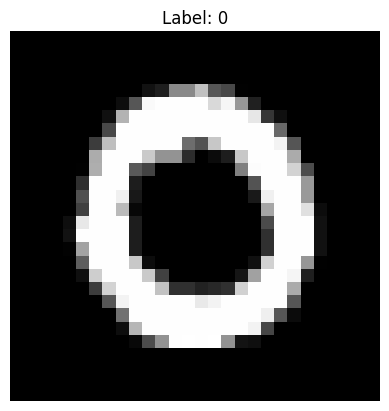

In [5]:
sample = train[1]

pixel_columns = [
    col for col in train.column_names
    if col.startswith('pixel')
]

image = np.array(
    [sample[col] for col in pixel_columns]
).reshape(28, 28)

plt.imshow(image, cmap='gray')
plt.title(f"Label: {sample['label']}")
plt.axis('off')
plt.show()

## 3. Data Preprocessing

Separate the pixel values from the labels and normalize the pixel values to the range [0, 1].

In [6]:
pixel_columns = [
    col for col in train.column_names
    if col.startswith('pixel')
]

X_train = np.array(
    train.select_columns(pixel_columns).to_pandas(),
    dtype=np.float32
)

y_train = np.array(train['label'])

X_train = X_train / 255.0

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("Pixel range:", X_train.min(), X_train.max())

X_train shape: (42000, 784)
y_train shape: (42000,)
Pixel range: 0.0 1.0


## 4. Build the Model

A fully connected neural network is used as the baseline model. It contains two hidden layers with ReLU activation and a 10-class softmax output layer.

In [7]:
model = keras.Sequential([
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer=keras.optimizers.Adam(),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

2026-10-26 10:11:48.992251: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 5. Train the Model

Train the neural network for 10 epochs and reserve 20% of the training data for validation.

In [8]:
hist = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=256,
    validation_split=0.2
)

Epoch 1/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8532 - loss: 0.5418 - val_accuracy: 0.9280 - val_loss: 0.2500
Epoch 2/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9398 - loss: 0.2062 - val_accuracy: 0.9458 - val_loss: 0.1865
Epoch 3/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9557 - loss: 0.1522 - val_accuracy: 0.9544 - val_loss: 0.1554
Epoch 4/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9646 - loss: 0.1209 - val_accuracy: 0.9618 - val_loss: 0.1319
Epoch 5/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9726 - loss: 0.0951 - val_accuracy: 0.9642 - val_loss: 0.1199
Epoch 6/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9750 - loss: 0.0818 - val_accuracy: 0.9632 - val_loss: 0.1166
Epoch 7/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9814 - loss: 0.0653 - val_accuracy: 0.9645 - val_loss: 0.1159
Epoch 8/10
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9831 - loss: 0.0542 - val_accuracy: 0.

## 6. Evaluate the Model

Compare training and validation accuracy across epochs to observe the model's learning behavior.

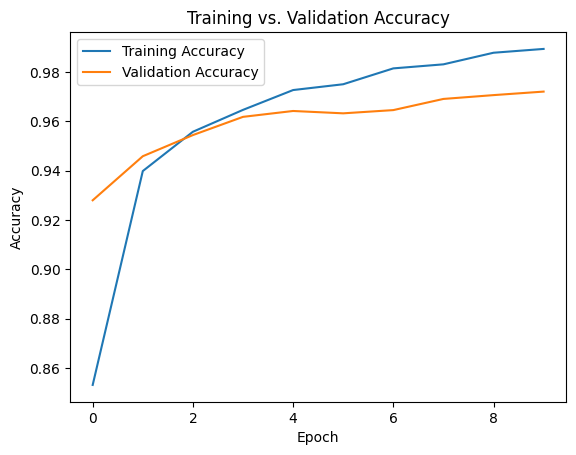

In [10]:
acc = hist.history['accuracy']
val_acc = hist.history['val_accuracy']

plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs. Validation Accuracy')
plt.legend()
plt.show()

## 7.  Training and Validation Accuracy

Display the final training and validation accuracy to compare the model's performance on the training data and the validation data.

In [11]:
print("Training accuracy:", hist.history['accuracy'][-1])
print("Validation accuracy:", hist.history['val_accuracy'][-1])

Training accuracy: 0.9893154501914978
Validation accuracy: 0.9720237851142883


## 8.  Inspect Test Dataset

Check the available columns in the test dataset to identify the pixel features and determine whether a label column is present.

In [12]:
print("Columns:", test.column_names)

Columns: ['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8', 'pixel9', 'pixel10', 'pixel11', 'pixel12', 'pixel13', 'pixel14', 'pixel15', 'pixel16', 'pixel17', 'pixel18', 'pixel19', 'pixel20', 'pixel21', 'pixel22', 'pixel23', 'pixel24', 'pixel25', 'pixel26', 'pixel27', 'pixel28', 'pixel29', 'pixel30', 'pixel31', 'pixel32', 'pixel33', 'pixel34', 'pixel35', 'pixel36', 'pixel37', 'pixel38', 'pixel39', 'pixel40', 'pixel41', 'pixel42', 'pixel43', 'pixel44', 'pixel45', 'pixel46', 'pixel47', 'pixel48', 'pixel49', 'pixel50', 'pixel51', 'pixel52', 'pixel53', 'pixel54', 'pixel55', 'pixel56', 'pixel57', 'pixel58', 'pixel59', 'pixel60', 'pixel61', 'pixel62', 'pixel63', 'pixel64', 'pixel65', 'pixel66', 'pixel67', 'pixel68', 'pixel69', 'pixel70', 'pixel71', 'pixel72', 'pixel73', 'pixel74', 'pixel75', 'pixel76', 'pixel77', 'pixel78', 'pixel79', 'pixel80', 'pixel81', 'pixel82', 'pixel83', 'pixel84', 'pixel85', 'pixel86', 'pixel87', 'pixel88', 'pixel89', '

In [20]:
print("Train label:", train[0]['label'])
print("Test label:", test[0]['label'])

print("Test labels that are None:",
      sum(test[i]['label'] is None for i in range(len(test))))

print("Total test samples:", len(test))

Train label: 1
Test label: None
Test labels that are None: 28000
Total test samples: 28000


In [14]:
pixel_columns = [
    col for col in test.column_names
    if col.startswith('pixel')
]

X_test = np.array(
    test.select_columns(pixel_columns).to_pandas(),
    dtype=np.float32
)

X_test = X_test / 255.0

print("X_test shape:", X_test.shape)
print("Pixel range:", X_test.min(), X_test.max())

X_test shape: (28000, 784)
Pixel range: 0.0 1.0


## 9.  Generate Predictions

Use the trained neural network to predict the digit for each image in the test dataset. The model outputs probabilities for 10 classes (digits 0–9). We use `np.argmax()` to select the digit with the highest predicted probability.



In [15]:
predictions = model.predict(X_test)

print("Predictions shape:", predictions.shape)
print("First 10 predictions:", np.argmax(predictions[:10], axis=1))

875/875 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Predictions shape: (28000, 10)
First 10 predictions: [2 0 9 9 3 7 0 3 0 3]


## 10.  Create Submission File

Convert the model's probability outputs into predicted digit labels, then create a CSV file in the format required by the Kaggle Digit Recognizer competition.

In [16]:
y_pred = np.argmax(predictions, axis=1)

submission = pd.DataFrame({
    'ImageId': np.arange(1, len(y_pred) + 1),
    'Label': y_pred
})

submission.to_csv('submission.csv', index=False)

print(submission.head())
print("Submission shape:", submission.shape)

   ImageId  Label
0        1      2
1        2      0
2        3      9
3        4      9
4        5      3
Submission shape: (28000, 2)


In [17]:
test_loss, test_accuracy = model.evaluate(
    X_train[-8400:],
    y_train[-8400:],
    verbose=0
)

print("Accuracy:", test_accuracy)

Accuracy: 0.9720237851142883


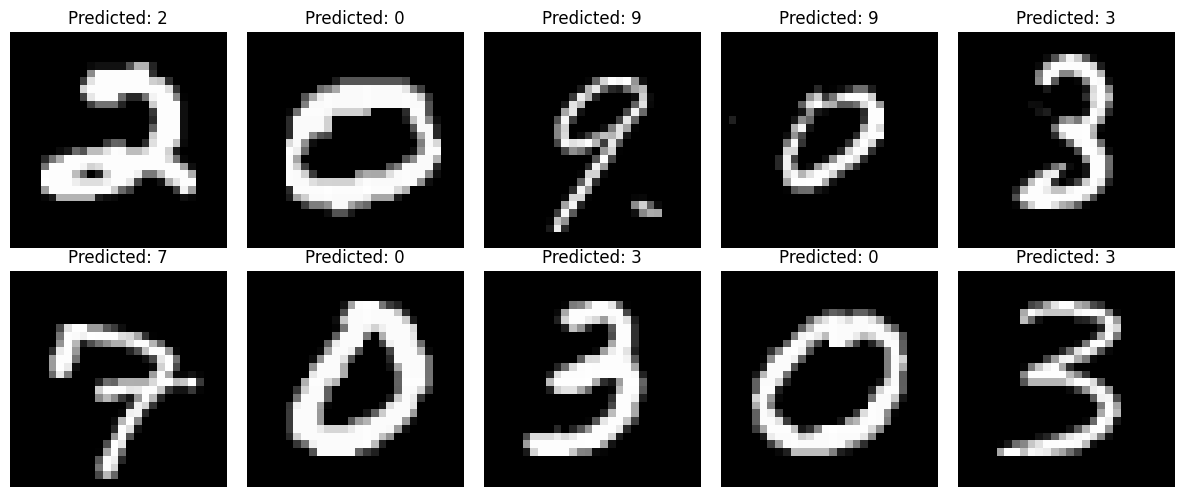

In [18]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"Predicted: {y_pred[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [19]:
print(submission.head())
print(submission.shape)
print(submission.isnull().sum())
print(submission.dtypes)

   ImageId  Label
0        1      2
1        2      0
2        3      9
3        4      9
4        5      3
(28000, 2)
ImageId    0
Label      0
dtype: int64
ImageId    int64
Label      int64
dtype: object
